# Práctica 3 — PLN para Inteligencia de Negocios

**Visitemos el sitio:**  https://spacy.io/


1. **Normalización `NFKC`** (preserva tildes y ñ).
2. **Negaciones contradictorias** → `handle_negations` antes de quitar stopwords en el pipeline clásico; `clean_light` en transformers.
3. **Prints masivos** → `display()`, `value_counts()` y gráficos.

Archivos necesarios: `Constitucion.txt`, `stopwords.es`, `Datos.csv`.


In [1]:
!pip install -q spacy
!python -m spacy download es_core_news_sm -q
!pip install -q pysentimiento wordcloud

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [1]:
import re
import string
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import spacy
from spacy.lang.es.stop_words import STOP_WORDS
from wordcloud import WordCloud

nlp = spacy.load("es_core_news_sm")
print("spaCy:", nlp.meta["name"], nlp.meta["version"])


spaCy: core_news_sm 3.8.0


## Utilidades compartidas
Corrección 1: `NFKC` en lugar de ASCII.  
Corrección 2: `handle_negations` antes de stopwords en el pipeline clásico; `clean_light` para transformers.


In [5]:
def normalize_text(text):
    """Corrección 1: NFKC preserva tildes, ñ y ü."""
    if not isinstance(text, str):
        return ""
    return unicodedata.normalize("NFKC", text)

def load_stopwords(path="stopwords.es"):
    if Path(path).exists():
        with open(path, encoding="utf-8") as f:
            return {line.strip() for line in f if line.strip()}
    return set()

NEGATION_WORDS = {"no", "nunca", "jamas", "jamás", "ni", "tampoco",
                  "ningun", "ningún", "ninguna", "nadie", "nada", "sin"}

def handle_negations(tokens):
    """Une negación + siguiente token. Debe aplicarse ANTES de quitar stopwords."""
    result, i = [], 0
    while i < len(tokens):
        if tokens[i] in NEGATION_WORDS and i + 1 < len(tokens):
            result.append(f"{tokens[i]}_{tokens[i + 1]}")
            i += 2
        else:
            result.append(tokens[i])
            i += 1
    return result

def preprocess_text(text, custom_stopwords=None):
    """Pipeline clásico: NFKC, limpieza, lematización, negaciones ANTES de stopwords."""
    if pd.isna(text):
        return []
    custom_stopwords = custom_stopwords or set()
    text = normalize_text(text).lower()
    text = re.sub(r"http[s]?://\S+", " ", text)
    text = re.sub(r"[^\w\sáéíóúüñ.,;:!?¿¡-]", " ", text, flags=re.UNICODE)
    doc = nlp(text)
    lemmas = [t.lemma_.lower() for t in doc
              if not t.is_space and not t.is_punct and not t.like_num and t.text.strip()]
    lemmas = handle_negations(lemmas)  # ANTES de stopwords
    spacy_stop = getattr(nlp.Defaults, "stop_words", set())
    final = []
    for tok in lemmas:
        if "_" in tok:  # par negado: conservar
            final.append(tok); continue
        if tok in custom_stopwords or tok in spacy_stop:
            continue
        final.append(tok)
    return final

def clean_light(text):
    """Limpieza mínima para transformers: NFKC, sin URLs, espacios colapsados."""
    if not isinstance(text, str) or not text.strip():
        return ""
    text = normalize_text(text)
    text = re.sub(r"http[s]?://\S+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize_raw_text(text):
    if pd.isna(text):
        return []
    doc = nlp(normalize_text(text))
    return [t.text for t in doc if not t.is_space]


## Procesamiento Constitución


,frecuencia
artículo,234
ley,211
derecho,140
gobierno,93
público,90
caso,84
comunidades,69
autónomas,69
constitución,65
cortes,56


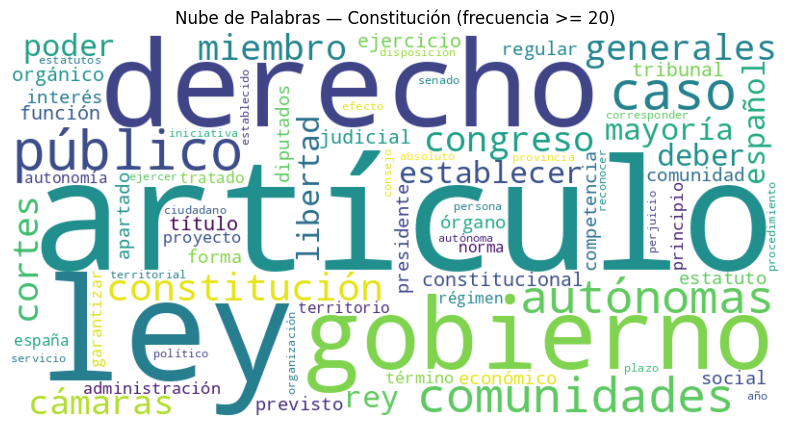

In [8]:
with open("Constitucion.txt", encoding="utf-8") as f:
    text = f.read()
text = normalize_text(text)  # Corrección 1
doc = nlp(text)
custom_stopwords = load_stopwords("stopwords.es")

processed_tokens = [t.lemma_.lower() for t in doc
                    if not t.is_stop and t.text.lower() not in custom_stopwords
                    and not t.is_punct and not t.is_space and not t.like_num
                    and t.text.strip()]

word_freq = Counter(processed_tokens)
filtered_word_freq = {w: f for w, f in word_freq.items() if f >= 20}

# Corrección 4: Series en lugar de prints masivos
display(pd.Series(dict(word_freq.most_common(20)), name="frecuencia").to_frame())

if filtered_word_freq:
    wordcloud = WordCloud(width=800, height=400, background_color="white",
                          colormap="viridis", max_words=100
                          ).generate_from_frequencies(filtered_word_freq)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Nube de Palabras — Constitución (frecuencia >= 20)")
    plt.show()


## Procesamiento de opinión de clientes


Filas: 50 | Columnas: ['ID', 'Source', 'Product', 'Rating', 'CommentText']


,ID,Source,Product,Rating,CommentText
0,REV-001,Amazon,TecnoGadget Headphones,5,El escenario sonoro es cinematográfico—rumor d...
1,REV-002,ForoX,TecnoGadget Phone,4,La pantalla AMOLED es super suave; la cámara I...
2,REV-003,Twitter,TecnoGadget Smartwatch,2,¿Por qué el sensor de ritmo cardíaco lee mal a...
3,REV-004,CustomerService,TecnoGadget Headphones,1,"Recibí un auricular defectuoso, sin respuesta ..."
4,REV-005,Amazon,TecnoGadget Phone,3,Rendimiento promedio; el procesador se reduce ...


,ID,CommentText,processed_tokens
0,REV-001,El escenario sonoro es cinematográfico—rumor d...,"[escenario, sonoro, cinematográfico, rumor, ag..."
1,REV-002,La pantalla AMOLED es super suave; la cámara I...,"[pantalla, amoled, super, suave, cámara, ia, e..."
2,REV-003,¿Por qué el sensor de ritmo cardíaco lee mal a...,"[sensor, ritmo, cardíaco, leer, 4:00, am, inte..."
3,REV-004,"Recibí un auricular defectuoso, sin respuesta ...","[recibir, auricular, defectuoso, sin_respuesta..."
4,REV-005,Rendimiento promedio; el procesador se reduce ...,"[rendimiento, promedio, procesador, reducir, c..."


,frecuencia
batería,28
cámara,15
soporte,11


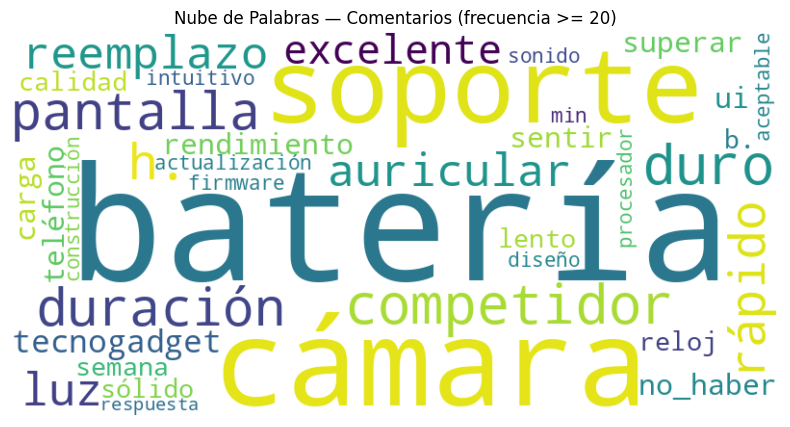

In [9]:
df = pd.read_csv("Datos.csv", delimiter=",", quotechar='"',
                 doublequote=True, escapechar="\\")
print(f"Filas: {len(df)} | Columnas: {df.columns.tolist()}")
display(df.head())

custom_stopwords = load_stopwords("stopwords.es")
df["processed_tokens"] = df["CommentText"].apply(
    lambda t: preprocess_text(t, custom_stopwords))

# Muestra, no print por fila
display(df[["ID", "CommentText", "processed_tokens"]].head(5))

all_tokens = [t for toks in df["processed_tokens"] for t in toks]
word_freq = Counter(all_tokens)
filtered_word_freq = {w: f for w, f in word_freq.items() if f >= 3}
display(pd.Series(dict(word_freq.most_common(3)), name="frecuencia").to_frame())

if filtered_word_freq:
    wordcloud = WordCloud(width=800, height=400, background_color="white",
                          colormap="viridis", max_words=100
                          ).generate_from_frequencies(filtered_word_freq)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Nube de Palabras — Comentarios (frecuencia >= 20)")
    plt.show()




In [10]:
for rating in sorted(df["Rating"].dropna().unique()):
    subset = df[df["Rating"] == rating]
    tokens = [t for toks in subset["processed_tokens"] for t in toks]
    top10 = pd.Series(dict(Counter(tokens).most_common(10)), name=f"rating_{rating}")
    display(top10.to_frame().T)

,soporte,reemplazo,semana,no_haber,auricular,defectuoso,prometer,nunca_llegar,pantalla,no_ofrecer
rating_1,8,5,4,4,2,2,2,2,2,2


,soporte,sentir,lento,actualización,firmware,teléfono,sobrecalientar,min,juego,térmico
rating_2,3,2,2,2,2,2,2,2,2,2


,batería,aceptable,duración,competidor,sonido,sentir,frágil,duro,intenso,ui
rating_3,7,3,3,2,2,2,2,2,2,2


,batería,cámara,sólido,luz,competidor,excelente,duro,duración,pantalla,ia
rating_4,9,6,4,3,3,3,3,3,2,2


,batería,cámara,rápido,superar,h.,tecnogadget,intuitivo,excelente,duro,nítido
rating_5,10,8,5,5,4,4,3,3,3,2


## Análisis descriptivo básico


In [11]:
df["raw_tokens"] = df["CommentText"].apply(tokenize_raw_text)
df["raw_length"] = df["raw_tokens"].apply(len)
df["processed_length"] = df["processed_tokens"].apply(len)

print(f"Comentarios: {len(df)}")
print(f"Longitud media antes: {df['raw_length'].mean():.2f} tokens")
print(f"Longitud media después: {df['processed_length'].mean():.2f} tokens")

raw_freq = Counter(t for toks in df["raw_tokens"] for t in toks)
proc_freq = Counter(t for toks in df["processed_tokens"] for t in toks)
display(pd.Series(dict(raw_freq.most_common(10)), name="antes").to_frame())
display(pd.Series(dict(proc_freq.most_common(10)), name="después").to_frame())
print(f"Vocabulario único antes: {len(raw_freq)} | después: {len(proc_freq)}")


Comentarios: 50
Longitud media antes: 20.28 tokens
Longitud media después: 8.58 tokens


,antes
.,84
de,57
es,36
La,34
la,30
El,28
batería,28
;,19
se,16
",",15


,después
batería,28
cámara,15
soporte,11
competidor,9
duro,9
pantalla,8
duración,8
h.,7
rápido,7
luz,6


Vocabulario único antes: 324 | después: 201


## Multilenguaje (BERT multilingüe)

Se emplea `clean_light`, **no** `preprocess_text`. Los transformers necesitan el texto natural.


In [14]:
# Login HF una sola vez (corrección 3)
from google.colab import userdata
from huggingface_hub import login
login(token=userdata.get("HF_TOKEN"))


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,ID,CommentText,sentiment_label,sentiment_score
0,REV-001,El escenario sonoro es cinematográfico—rumor d...,POSITIVE,0.516310
1,REV-002,La pantalla AMOLED es super suave; la cámara I...,POSITIVE,0.412840
2,REV-003,¿Por qué el sensor de ritmo cardíaco lee mal a...,NEGATIVE,0.418606
3,REV-004,"Recibí un auricular defectuoso, sin respuesta ...",NEGATIVE,0.742265
4,REV-005,Rendimiento promedio; el procesador se reduce ...,NEUTRAL,0.644811
5,REV-006,Precisión GPS excelente; la batería dura 7 día...,POSITIVE,0.729692
6,REV-007,Carga rápida (0–100 % en 30 min) y construcció...,POSITIVE,0.758637
7,REV-008,He llamado 3 veces por una pantalla rota; no o...,NEGATIVE,0.696527
8,REV-009,"Los controles táctiles responden bien, pero la...",NEUTRAL,0.497364
9,REV-010,El teléfono se sobrecalienta después de 30 min...,NEGATIVE,0.573408


,count
sentiment_label,
POSITIVE,20
NEGATIVE,20
NEUTRAL,10


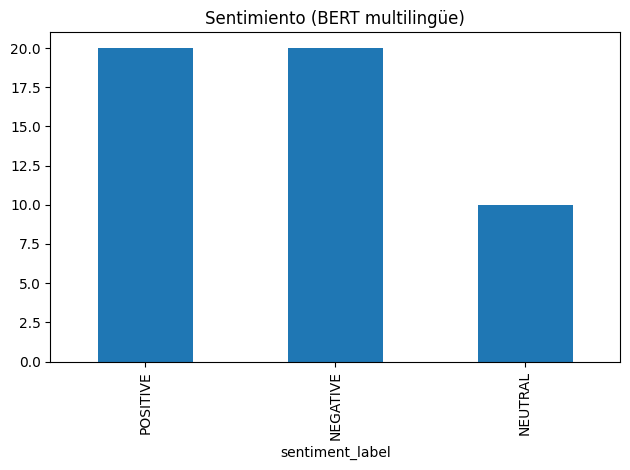

In [16]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    return_all_scores=False,
)

def classify_sentiment(text):
    if pd.isna(text):
        return {"label": "NEUTRAL", "score": 0.0}
    result = sentiment_pipeline(clean_light(text))[0]
    label, score = result["label"], result["score"]
    if "5" in label or "4" in label:
        polarity = "POSITIVE"
    elif "1" in label or "2" in label:
        polarity = "NEGATIVE"
    else:
        polarity = "NEUTRAL"
    return {"label": polarity, "score": score}

sent = df["CommentText"].apply(classify_sentiment)
df["sentiment_label"] = sent.apply(lambda x: x["label"])
df["sentiment_score"] = sent.apply(lambda x: x["score"])

display(df[["ID", "CommentText", "sentiment_label", "sentiment_score"]].head(10))
display(df["sentiment_label"].value_counts().to_frame())
df["sentiment_label"].value_counts().plot(kind="bar", title="Sentimiento (BERT multilingüe)")
plt.tight_layout(); plt.show()


## Modelo específico español (pysentimiento)


In [17]:
from pysentimiento import create_analyzer

analyzer = create_analyzer(task="sentiment", lang="es")

def classify_sentiment_spanish(text):
    if pd.isna(text):
        return {"label": "NEUTRAL", "score": 0.0}
    result = analyzer.predict(clean_light(text))
    return {"label": result.output.upper(),
            "score": float(max(result.probas.values()))}

sent = df["CommentText"].apply(classify_sentiment_spanish)
df["sentiment_label_es"] = sent.apply(lambda x: x["label"])
df["sentiment_score_es"] = sent.apply(lambda x: x["score"])

display(df[["ID", "CommentText", "sentiment_label_es", "sentiment_score_es"]].head(10))
display(df["sentiment_label_es"].value_counts().to_frame())
display(df.groupby("sentiment_label_es")["sentiment_score_es"].mean().to_frame())


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

,ID,CommentText,sentiment_label_es,sentiment_score_es
0,REV-001,El escenario sonoro es cinematográfico—rumor d...,POS,0.694117
1,REV-002,La pantalla AMOLED es super suave; la cámara I...,POS,0.823072
2,REV-003,¿Por qué el sensor de ritmo cardíaco lee mal a...,NEG,0.955352
3,REV-004,"Recibí un auricular defectuoso, sin respuesta ...",NEG,0.894718
4,REV-005,Rendimiento promedio; el procesador se reduce ...,NEU,0.846857
5,REV-006,Precisión GPS excelente; la batería dura 7 día...,NEU,0.715823
6,REV-007,Carga rápida (0–100 % en 30 min) y construcció...,POS,0.819479
7,REV-008,He llamado 3 veces por una pantalla rota; no o...,NEG,0.908116
8,REV-009,"Los controles táctiles responden bien, pero la...",NEU,0.636394
9,REV-010,El teléfono se sobrecalienta después de 30 min...,NEG,0.964794


,count
sentiment_label_es,
NEG,21
POS,17
NEU,12


,sentiment_score_es
sentiment_label_es,
NEG,0.855874
NEU,0.737850
POS,0.779065


## TODO (estudiante)

El notebook original no incluía NER, LDA, sentimiento por aspecto ni tablas de decisión. Se dejan como ampliación:

- `extract_entities` con `doc.ents`.
- LDA con `CountVectorizer` + `LatentDirichletAllocation`.
- Cruce de aspectos (`ASPECT_TAXONOMY`) con `sentiment_label`.
- Tablas que respondan a las 3 preguntas decisionales.
